# Chapitre 10 - Exercices 10.6 à 10.11

Ce notebook traite six exercices sur les caches, l'observabilité, l'orchestration et les
retours utilisateurs (cours 2 à 4) :

- **10.6** : le seuil optimal d'un cache sémantique et sa robustesse (calcul + mini-lab) ;
- **10.7** : reproduire et corriger une fuite de données par le cache (mini-lab) ;
- **10.8** : régler une alerte CUSUM : fausses alertes contre délai de détection (calcul + simulation) ;
- **10.9** : chemin critique d'un pipeline et placement d'un garde-fou lent (calcul) ;
- **10.10** : apprendre un score de satisfaction implicite à partir des signaux (mini-lab) ;
- **10.11** : biais de position, puissance statistique et boucle de rétroaction (calcul + simulation).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from aie.plotting import set_style, INDIGO, TEAL, AMBER, ROSE, VIOLET, SKY, SLATE, GRAY, GREEN, COLORS, annotate_bars
from aie import llm
from aie import ch10_architecture as A

set_style()
pd.set_option("display.max_colwidth", 90)
rng = np.random.default_rng(0)
embed = lambda texts: llm.embed(texts, llm.EMBED_MULTI)

## Exercice 10.6 : Le seuil optimal d'un cache sémantique

**Énoncé.** (1) Avec les notations du cours 2 ($h$ taux de succès, $e$ taux d'erreur, $c$ coût
d'un appel, $c_{lk}$ coût de la recherche dans le cache, $c_{err}$ coût d'une mauvaise
réponse), donner la condition pour que le cache sémantique soit rentable. (2) Sur le flux
`A.CACHE_QUERIES`, calculer le seuil optimal $\tau^*$ pour $c_{err} \in \{0, 1, 2, 5, 10, 20\}$
(en unités de $c$, avec $c_{lk} = 0{,}02$). (3) Le taux de succès dépend de l'**ordre**
d'arrivée des requêtes : mesurer sa variabilité sur 200 ordres aléatoires au seuil 0,8.
(4) Que devient la rentabilité si seule une fraction $\rho$ du trafic réel ressemble à ce jeu
(le reste n'a jamais de paraphrase en cache) ?

**Rappels.** Section *Semantic caching* : le cache sémantique n'a de valeur que si le taux
de succès est élevé ; sa recherche vectorielle coûte à chaque requête et une erreur renvoie
la réponse à une autre question. Cours 2 : $\bar c = c_{lk} + (1-h)\,c + e\,c_{err}$.

**Solution.** (1) Le cache est rentable si $\bar c < c$, soit
$$h\,c > c_{lk} + e\,c_{err} :$$
l'économie des succès doit couvrir le coût fixe de la recherche **et** le coût des erreurs.

(2) On évalue $\bar c(\tau)$ sur une grille et on prend l'argmin (ci-dessous).

(4) Sur une fraction $1-\rho$ du trafic, aucune paraphrase n'existe : au mieux pas de succès
(et, pour un seuil bas, de faux succès). En première approximation $h \to \rho h$ et
$e \to \rho e + (1-\rho) e_0$, où $e_0$ est le taux de faux succès sur des requêtes sans
paraphrase. Avec $e_0 \approx 0$ (seuil assez haut), la condition devient
$\rho\,(h c - e\,c_{err}) > c_{lk}$ : il faut $\rho > c_{lk}/(h c - e c_{err})$.

In [2]:
cq = [q for q, _ in A.CACHE_QUERIES]; cg = np.array([g for _, g in A.CACHE_QUERIES])
Ec = embed(cq)
thr = np.linspace(0.5, 1.0, 51)
st = A.pairwise_cache_stats(Ec, cg, thr)
c, c_lk = 1.0, 0.02
rows = []
for c_err in [0, 1, 2, 5, 10, 20]:
    cost = c_lk + (1 - st["hit_rate"]) * c + st["err_rate"] * c_err
    j = int(np.argmin(cost))
    rows.append({"c_err": c_err, "tau*": thr[j], "h": st["hit_rate"][j], "e": st["err_rate"][j], "coût": cost[j],
                 "gain vs sans cache": 1 - cost[j] / c})
opt = pd.DataFrame(rows); opt.round(3)

,c_err,tau*,h,e,coût,gain vs sans cache
0,0,0.50,0.667,0.194,0.353,0.647
1,1,0.54,0.611,0.139,0.548,0.452
2,2,0.54,0.611,0.139,0.687,0.313
3,5,0.82,0.194,0.000,0.826,0.174
4,10,0.82,0.194,0.000,0.826,0.174
5,20,0.82,0.194,0.000,0.826,0.174


**Vérification** (3) : variabilité due à l'ordre, et (4) : rentabilité selon $\rho$.

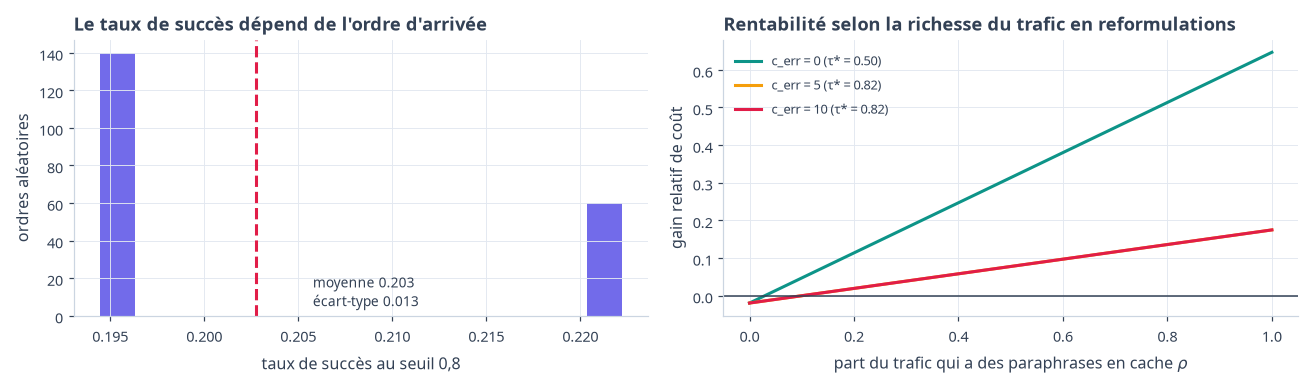

In [3]:
hits = []
for s in range(200):
    perm = np.random.default_rng(s).permutation(len(cq))
    hits.append(A.pairwise_cache_stats(Ec[perm], cg[perm], [0.8])["hit_rate"][0])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(hits, bins=15, color=INDIGO, alpha=0.8)
ax[0].axvline(np.mean(hits), color=ROSE, ls="--"); ax[0].text(np.mean(hits) + 0.003, 5, f"moyenne {np.mean(hits):.3f}\nécart-type {np.std(hits):.3f}", fontsize=9)
ax[0].set(xlabel="taux de succès au seuil 0,8", ylabel="ordres aléatoires", title="Le taux de succès dépend de l'ordre d'arrivée")
rhos = np.linspace(0, 1, 101)
for c_err, col in [(0, TEAL), (5, AMBER), (10, ROSE)]:
    r = opt[opt.c_err == c_err].iloc[0]
    ax[1].plot(rhos, 1 - (c_lk + (1 - rhos * r.h) * c + rhos * r.e * c_err) / c, color=col, label=f"c_err = {c_err} (τ* = {r['tau*']:.2f})")
ax[1].axhline(0, color=SLATE, lw=1)
ax[1].set(xlabel="part du trafic qui a des paraphrases en cache $\\rho$", ylabel="gain relatif de coût",
          title="Rentabilité selon la richesse du trafic en reformulations")
ax[1].legend(fontsize=8.5); plt.tight_layout(); plt.show()

Le seuil optimal **remonte** quand le coût d'une erreur augmente, et le gain fond. L'ordre
d'arrivée change le taux de succès de quelques points (sur 36 requêtes, chaque succès pèse
près de 3 %) : un réglage fait sur un petit échantillon est fragile. Enfin, quand le trafic
contient peu de reformulations ($\rho$ faible), le gain devient négatif : le coût fixe de la
recherche n'est plus couvert.

> **À retenir.** Cache sémantique rentable $\iff h\,c > c_{lk} + e\,c_{err}$ ; le seuil
> optimal croît avec le coût des erreurs, et tout dépend de la part réelle de reformulations.

## Exercice 10.7 : Reproduire et corriger une fuite de données par le cache

**Énoncé.** Le livre décrit une fuite : une question d'apparence générique (« quelle est la
politique de retour ? ») reçoit une réponse construite à partir du profil de l'utilisateur
(membre premium ou standard), la réponse est mise en cache puis servie à un autre
utilisateur. (1) Simuler 2 000 requêtes de 60 utilisateurs (deux segments) avec un cache
exact naïf et compter les réponses **fausses ou fuitées**. (2) Comparer trois corrections :
filtrer les requêtes personnelles (`A.is_cacheable`), inclure le segment dans la clé,
combiner les deux. (3) Mesurer pour chacune le taux de succès conservé.

**Rappels.** Section *Exact caching* (encadré) : une mise en cache mal maîtrisée peut causer
des fuites ; les requêtes spécifiques à un utilisateur ne doivent pas être mises en cache.
Cours 2 : `ExactCache.get(query, scope=...)` permet d'inclure un contexte dans la clé.

**Solution.** Trois familles de requêtes : **génériques** (même réponse pour tous),
**dépendantes du segment** (politique de retour, frais de livraison) et **personnelles**
(« où en est ma commande ? »). La réponse correcte dépend respectivement de rien, du
segment, de l'utilisateur. Une réponse servie par le cache est une **fuite** si elle a été
calculée pour un autre utilisateur et qu'elle diffère de la bonne réponse.

In [4]:
generic = ["Quels moyens de paiement acceptez-vous ?", "Où se trouve le magasin de Lyon ?", "Comment changer de mot de passe ?"]
segment_dep = ["Quelle est la politique de retour ?", "Combien coûte la livraison ?"]
personal = ["Où en est ma commande ?", "Quel est mon solde de points fidélité ?"]
users = {f"u{i}": ("premium" if i % 3 == 0 else "standard") for i in range(60)}

def true_answer(q, u):
    if q in generic:
        return f"réponse générique à « {q} »"
    if q in segment_dep:
        return f"réponse pour le segment {users[u]} à « {q} »"
    return f"réponse personnelle pour {u} à « {q} »"

def run(strategy, n=2000, seed=0):
    r = np.random.default_rng(seed)
    cache = A.ExactCache(capacity=10_000)
    leaks = wrong = hits = 0
    pool = generic * 3 + segment_dep * 2 + personal
    for _ in range(n):
        u = f"u{r.integers(60)}"; q = pool[r.integers(len(pool))]
        use = strategy != "sans cache" and (strategy in ("naïf", "segment dans la clé") or A.is_cacheable(q))
        scope = users[u] if strategy in ("segment dans la clé", "filtre + segment") else ""
        ans = cache.get(q, scope) if use else None
        hits += ans is not None
        if ans is None:
            ans = (true_answer(q, u), u)
            if use:
                cache.put(q, ans, scope)
        served, owner = ans
        if served != true_answer(q, u):
            wrong += 1
            leaks += owner != u and q in personal
    return {"stratégie": strategy, "taux de succès": hits / n,
            "réponses fausses": wrong, "dont données personnelles d'autrui": leaks}

res = pd.DataFrame([run(s) for s in ["naïf", "filtre is_cacheable", "segment dans la clé", "filtre + segment", "sans cache"]])
res

,stratégie,taux de succès,réponses fausses,dont données personnelles d'autrui
0,naïf,0.9965,510,250
1,filtre is_cacheable,0.8690,260,0
2,segment dans la clé,0.9930,244,244
3,filtre + segment,0.8665,0,0
4,sans cache,0.0000,0,0


**Vérification** graphique.

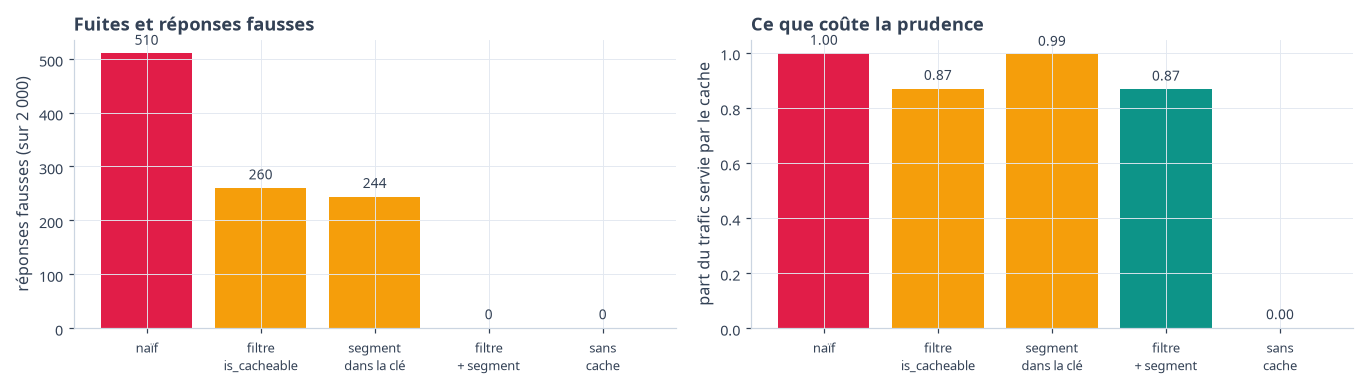

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.6))
cols = [ROSE, AMBER, AMBER, TEAL, GRAY]
ax[0].bar(range(len(res)), res["réponses fausses"], color=cols); annotate_bars(ax[0], "{:.0f}")
ax[0].set_xticks(range(len(res)), [s.replace(" ", "\n", 1) for s in res["stratégie"]], fontsize=8.5)
ax[0].set(ylabel="réponses fausses (sur 2 000)", title="Fuites et réponses fausses")
ax[1].bar(range(len(res)), res["taux de succès"], color=cols); annotate_bars(ax[1], "{:.2f}")
ax[1].set_xticks(range(len(res)), [s.replace(" ", "\n", 1) for s in res["stratégie"]], fontsize=8.5)
ax[1].set(ylabel="part du trafic servie par le cache", title="Ce que coûte la prudence")
plt.tight_layout(); plt.show()

Le cache naïf sert des centaines de réponses fausses, dont des données personnelles d'autres
clients. Le filtre `is_cacheable` supprime les fuites personnelles (« ma commande ») mais
laisse passer l'erreur de segment, car « quelle est la politique de retour ? » a l'air
générique : c'est exactement le piège de l'encadré du livre. Mettre le segment dans la clé
corrige l'erreur de segment mais pas les requêtes personnelles. Seule la combinaison
élimine toutes les erreurs ; elle renonce au cache pour les requêtes personnelles et
fragmente un peu le cache par segment, mais conserve l'essentiel des succès (les requêtes
génériques et de segment restent partagées). Principe : **la clé de cache doit contenir tout ce dont
dépend la réponse**.

> **À retenir.** Une fuite par le cache vient d'une clé incomplète ; filtrez les requêtes
> personnelles et incluez dans la clé le contexte (segment, langue, version) qui
> conditionne la réponse.

## Exercice 10.8 : Régler une alerte CUSUM

**Énoncé.** Une métrique horaire (centrée réduite) est surveillée par un CUSUM bilatéral de
marge $k = 0{,}5$. (1) Trouver par simulation le plus petit seuil $h$ qui garantit en moyenne
au plus **une fausse alerte par mois** (720 heures). (2) Pour ce $h$, mesurer le délai de
détection de sauts de $0{,}5\sigma$, $1\sigma$ et $2\sigma$ et le comparer à l'approximation
de Siegmund (voir la solution).
(3) Comparer à un détecteur « moyenne glissante sur 24 h au-dessus d'un seuil » réglé pour le
même taux de fausses alertes.

**Rappels.** Section *Drift detection* et cours 3 : $S^+_t = \max(0, S^+_{t-1} + z_t - k)$,
alerte si $S > h$. Le délai de détection fixe le MTTD, les fausses alertes la fatigue
d'astreinte.

**Solution.** (1) Sur une série stable, le nombre moyen d'alertes par 720 heures décroît
très vite avec $h$ (la durée moyenne entre fausses alertes croît exponentiellement avec $h$).
On balaie $h$ et on prend le premier sous 1.

(2) Intuition : après le saut, $z_t - k$ a pour moyenne $\Delta = \delta - k$ et le CUSUM
monte en moyenne de $\Delta$ par heure ; il lui faut environ $h/\Delta$ heures pour franchir
le seuil. L'approximation de Siegmund affine ce raisonnement (marche aléatoire avec
dépassement du seuil) : avec $b = h + 1{,}166$,
$$\text{délai} \approx \frac{e^{-2\Delta b} + 2\Delta b - 1}{2\Delta^2} \quad (\Delta \ne 0),
  \qquad \text{délai} \approx b^2 \quad (\Delta = 0).$$
Pour $\delta = 0{,}5 = k$, la dérive moyenne est nulle : le CUSUM ne progresse que par
fluctuations, d'où un délai en $b^2$, très lent.

In [6]:
def false_alarms_per_month(h, n_series=60, detector="cusum", thr=None):
    out = []
    for s in range(n_series):
        x = np.random.default_rng(1000 + s).normal(0, 1, 720)
        if detector == "cusum":
            out.append(len(A.cusum(x, target=0, sigma=1, k=0.5, h=h)[2]))
        else:
            ma = pd.Series(x).rolling(24).mean().values
            above = np.abs(np.nan_to_num(ma)) > thr
            out.append(int(np.sum(above[1:] & ~above[:-1])))      # nombre de franchissements
    return np.mean(out)

hs = np.arange(2.0, 9.1, 0.5)
fa = np.array([false_alarms_per_month(h) for h in hs])
h_star = hs[np.argmax(fa <= 1)]
print(f"h* = {h_star} ({fa[np.argmax(fa <= 1)]:.2f} fausse alerte par mois)")

def delay(h, delta, n=60, detector="cusum", thr=None):
    out = []
    for s in range(n):
        r = np.random.default_rng(s)
        x = np.concatenate([r.normal(0, 1, 100), r.normal(delta, 1, 600)])
        if detector == "cusum":
            f = A.first_alarm_after(A.cusum(x, target=0, sigma=1, k=0.5, h=h)[2], 100)
        else:
            ma = pd.Series(x).rolling(24).mean().values
            idx = np.where(np.abs(np.nan_to_num(ma[100:])) > thr)[0]
            f = 100 + idx[0] if len(idx) else None
        out.append((f - 100) if f is not None else 600)
    return np.mean(out)

def siegmund(h, delta, k=0.5):
    b, D = h + 1.166, delta - k
    return b ** 2 if abs(D) < 1e-9 else (np.exp(-2 * D * b) + 2 * D * b - 1) / (2 * D ** 2)

# seuil de la moyenne glissante donnant le même taux de fausses alertes
thrs = np.linspace(0.4, 0.9, 26)
fa_ma = np.array([false_alarms_per_month(None, detector="ma", thr=t) for t in thrs])
thr_star = thrs[np.argmax(fa_ma <= 1)]
deltas = [0.5, 1.0, 2.0]
tab = pd.DataFrame({"saut (σ)": deltas,
                    "CUSUM simulé (h)": [delay(h_star, d) for d in deltas],
                    "approximation (h)": [siegmund(h_star, d) for d in deltas],
                    "moyenne glissante 24 h (h)": [delay(None, d, detector="ma", thr=thr_star) for d in deltas]})
tab.round(1)

h* = 6.0 (0.55 fausse alerte par mois)


,saut (σ),CUSUM simulé (h),approximation (h),moyenne glissante 24 h (h)
0,0.5,46.5,51.4,38.0
1,1.0,9.6,12.3,13.2
2,2.0,3.2,4.6,6.8


**Vérification** graphique.

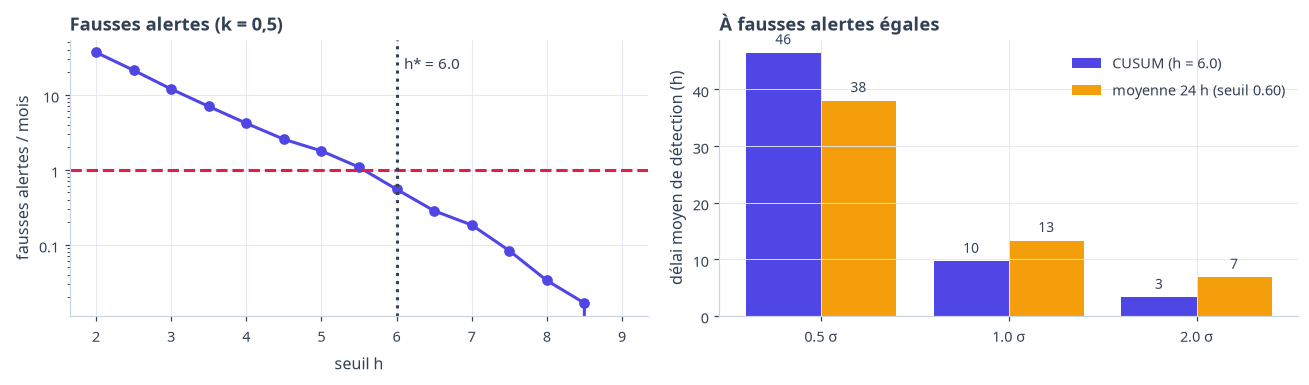

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].plot(hs, fa, "o-", color=INDIGO); ax[0].axhline(1, color=ROSE, ls="--")
ax[0].axvline(h_star, color=SLATE, ls=":"); ax[0].text(h_star + 0.1, fa.max() * 0.6, f"h* = {h_star}", fontsize=10)
ax[0].set(yscale="log", xlabel="seuil h", ylabel="fausses alertes / mois", title="Fausses alertes (k = 0,5)")
ax[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}")); ax[0].yaxis.set_minor_formatter(plt.NullFormatter())
x = np.arange(3)
ax[1].bar(x - 0.2, tab["CUSUM simulé (h)"], 0.4, color=INDIGO, label=f"CUSUM (h = {h_star})")
ax[1].bar(x + 0.2, tab["moyenne glissante 24 h (h)"], 0.4, color=AMBER, label=f"moyenne 24 h (seuil {thr_star:.2f})")
annotate_bars(ax[1], "{:.0f}")
ax[1].set_xticks(x, [f"{d} σ" for d in deltas]); ax[1].set(ylabel="délai moyen de détection (h)", title="À fausses alertes égales")
ax[1].legend(); plt.tight_layout(); plt.show()

L'approximation donne le bon ordre de grandeur et la bonne tendance ; elle surestime un peu
le délai simulé, car au moment du saut le CUSUM est souvent déjà au-dessus de zéro (petite
« avance » accumulée par le bruit). Pour $\delta = k$ la détection est lente, comme prévu.
À taux de fausses alertes égal, le CUSUM détecte plus vite qu'une moyenne glissante pour
les sauts nets ($1\sigma$, $2\sigma$), car la moyenne « attend » que sa fenêtre se remplisse
de valeurs décalées ; pour le petit saut ($0{,}5\sigma$), la moyenne glissante fait aussi
bien voire mieux. Un CUSUM est optimisé pour une taille de saut : on choisit
$k \approx \delta/2$ pour le saut que l'on veut détecter.

> **À retenir.** Le seuil $h$ se règle sur un budget de fausses alertes ; le délai vaut
> alors environ $h/(\delta - k)$ heures (approximation de Siegmund pour plus de précision),
> ce qui fixe le MTTD atteignable.